# Segmentation de clients avec K-means

**Objectif :** regrouper automatiquement les clients d'une boutique selon leur comportement d'achat, à partir de deux variables :
- `visites` : nombre de visites du client
- `panier` : montant moyen de son panier (en €)

C'est un problème d'**apprentissage non supervisé** : on ne connaît pas à l'avance les groupes de clients, l'algorithme doit les découvrir seul.

**Étapes du projet :**
1. Chargement et exploration des données
2. Visualisation du nuage de points
3. Standardisation des variables
4. Clustering avec K-means (k = 4)
5. Évaluation (inertie) et visualisation des clusters et des centroïdes
6. Interprétation des profils de clients

**Outils :** Python, pandas, matplotlib, scikit-learn

## 1. Chargement des données

In [ ]:
import pandas as pd                                   
import matplotlib.pyplot as plt                       
from sklearn.preprocessing import StandardScaler      
from sklearn.cluster import KMeans                    
# Chargement du jeu de données (600 clients)
df = pd.read_csv("boutique.csv")
print(df)

    client_id  visites  panier
0       B2258       18   28.07
1       B2329       19   30.60
2       B2241       18   11.60
3       B2487        7   71.97
4       B2224       19   20.81
..        ...      ...     ...
595     B2373        9   45.96
596     B2478       10   75.22
597     B2420        8  107.79
598     B2323       15   24.53
599     B2062        2   41.03

[600 rows x 3 columns]


## 2. Exploration des données

In [ ]:
print(df.info())
print("___________________________________________________")


print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   client_id  600 non-null    object 
 1   visites    600 non-null    int64  
 2   panier     600 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 14.2+ KB
None
___________________________________________________
          visites      panier
count  600.000000  600.000000
mean     8.126667   80.010467
std      6.660172   80.372919
min      1.000000    6.590000
25%      2.000000   23.777500
50%      6.000000   34.270000
75%     13.000000  104.485000
max     26.000000  313.820000


**Observations :**
- 600 clients, aucune valeur manquante.
- `client_id` est un identifiant : il ne sera pas utilisé pour le clustering.

## 3. Visualisation du nuage de points

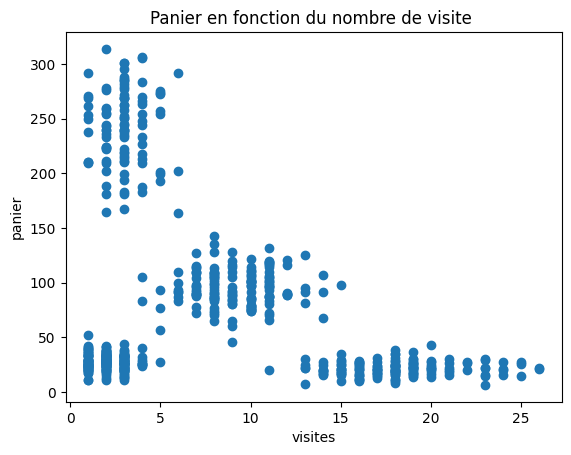

In [ ]:
x = df["visites"]
y = df["panier"]

plt.scatter(x, y)
plt.xlabel("Visites")
plt.ylabel("Panier (€)")
plt.title("Panier en fonction du nombre de visites")
plt.show()

**Combien de groupes voit-on ?** On distingue visuellement **4 groupes** :
- peu de visites (1 à 6), panier élevé (160 à 310 €)
- peu de visites (1 à 5), panier faible (10 à 50 €)
- visites moyennes (5 à 15), panier moyen (50 à 140 €)
- beaucoup de visites (13 à 26), panier faible (5 à 40 €)

Il n'y a **pas de relation linéaire** entre les deux variables : une régression linéaire ne serait pas adaptée. Le nuage suggère plutôt une **segmentation**.

## 4. Comparaison des échelles

In [ ]:
print(df[["visites", "panier"]].min())
print(df[["visites", "panier"]].max())

visites    1.00
panier     6.59
dtype: float64
visites     26.00
panier     313.82
dtype: float64


Les deux variables n'ont pas du tout la même échelle : les visites vont de 1 à 26, le panier de 6,59 à 313,82 €.

K-means calcule des **distances** entre les points. Sans mise à l'échelle, le panier (aux écarts beaucoup plus grands) dominerait le calcul et les visites ne compteraient presque pas. Il faut donc **standardiser**.

## 5. Standardisation

In [ ]:
X = df[["visites", "panier"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.mean(axis=0))   
print(X_scaled.std(axis=0))

[-2.96059473e-17  8.28966525e-17]
[1. 1.]


## 6. Clustering avec K-means (k = 4)

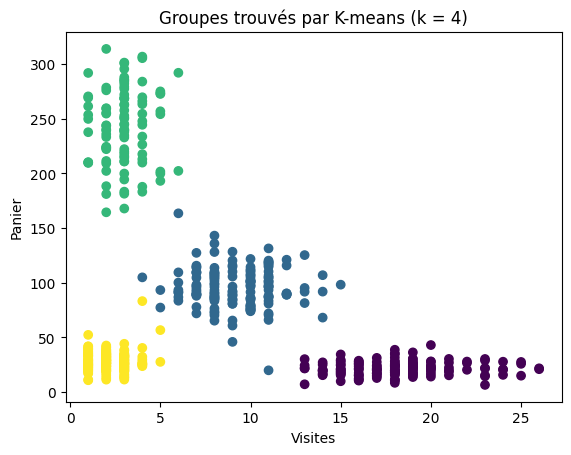

In [ ]:
k_means = KMeans(n_clusters=4, n_init=10, random_state=42)
k_means.fit(X_scaled)
labels = k_means.labels_
plt.scatter(x, y, c=labels, cmap="viridis")
plt.xlabel("Visites")
plt.ylabel("Panier (€)")
plt.title("Groupes trouvés par K-means (k = 4)")
plt.show()

## 7. Inertie

In [24]:
# Inertie : somme des distances au carré entre chaque point et le centre de son cluster
# Plus elle est faible, plus les clusters sont compacts
print(k_means.inertia_)

78.12900677612043


L'inertie obtenue est de **78,13**.

Pour l'interpréter : sur des données standardisées à 2 colonnes, l'inertie avec un seul cluster vaut 2 × 600 = 1200. Passer à 4 clusters réduit donc la dispersion d'environ **93 %** : les groupes sont compacts et bien séparés.

## 8. Clusters et centroïdes

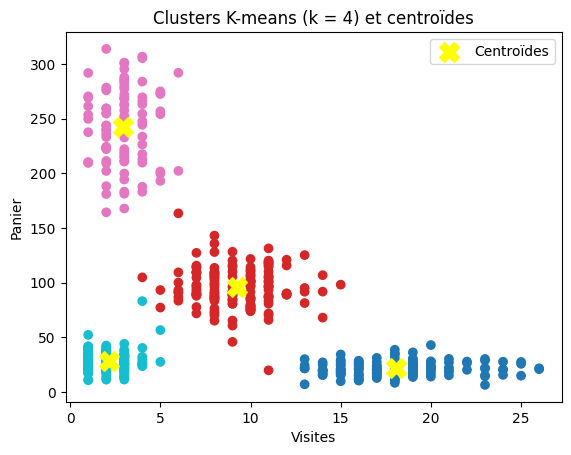

In [ ]:
centres = scaler.inverse_transform(k_means.cluster_centers_)
plt.scatter(x, y, c=k_means.labels_, cmap="tab10")
plt.scatter(centres[:, 0], centres[:, 1],
            c="yellow", marker="X", s=200, label="Centroïdes")

plt.xlabel("Visites")
plt.ylabel("Panier (€)")
plt.title("Clusters K-means (k = 4) et centroïdes")
plt.legend()
plt.show()

## 9. Interprétation des résultats

K-means retrouve les **4 groupes** identifiés visuellement, et chaque centroïde est placé au centre de son groupe.

| Profil | Centre (environ) | Description | Action possible |
|---|---|---|---|
| **Gros acheteurs** | 3 visites, 240 € | Viennent peu mais dépensent beaucoup | Programme VIP, offres premium |
| **Réguliers** | 9 visites, 95 € | Visites et panier moyens | Programme de fidélité |
| **Occasionnels** | 2 visites, 28 € | Viennent peu et dépensent peu | Promotions pour les faire revenir |
| **Visiteurs fréquents** | 18 visites, 22 € | Viennent souvent mais achètent peu | Comprendre les freins à l'achat, offres pour augmenter le panier |

Quelques points situés aux frontières entre deux groupes sont ambigus, ce qui est normal : K-means affecte chaque point au centroïde le plus proche.

## Conclusion

La segmentation K-means permet d'identifier 4 profils de clients distincts. La boutique peut s'en servir pour adapter sa stratégie marketing à chaque groupe plutôt que de traiter tous ses clients de la même façon.

**Pistes d'amélioration :**
- confirmer le choix de k avec la méthode du coude et le score de silhouette ;
- ajouter d'autres variables (ancienneté, catégories de produits achetés…).